# Quick study: one call from folder to tables

`run_study` runs a whole temperature study: it works out which file is which, drops stored spectra acquired with other settings, picks NIST lines per element, removes the baseline, integrates, and builds the ratio and scatter tables. You choose four things:

| | here |
|---|---|
| **folder** | `data/end_to_end` |
| **how files map to element / sample / temperature** | a pattern (or a manifest CSV) |
| **elements** | Ce, Gd |
| **baseline** | `'snip'` or `'airpls'` |

It needs the NIST database once (`libs-viewer nist build`). [end_to_end_temp_study.ipynb](end_to_end_temp_study.ipynb) walks through the same steps one by one.

In [1]:
from pathlib import Path

import libs_viewer.libs as LV
from libs_viewer.libs.plotting import plot_baseline, plot_spectrum, plot_study

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())

## 1. Check the file mapping

The pattern is matched against every `.tdms` path under the folder. `{element}`, `{sample}` and `{temperature}` are captured, and `*` stands for any text within one folder or file name. Here `Ce/1_wt%/Ce1_300C.tdms` gives element Ce, sample `1_wt%` and temperature 300.

Listing the temperatures also catches names where the temperature is glued to other digits (`Ce1400.tdms` → 400). Any file that doesn't match raises an error, so nothing is silently guessed. `study_plan` shows the mapping before anything is analysed:

In [2]:
FOLDER = ROOT / 'data' / 'libs_data' / 'Conference_Data'
PATTERN = '{element}/{sample}/*{temperature}*'
TEMPERATURES = [300, 350, 400]

LV.study_plan(FOLDER, pattern=PATTERN, temperatures=TEMPERATURES)

,file,element,sample,temperature,use_columns
0,Ce/Ce_1/Ce_Sample1_300C.tdms,Ce,Ce Ce_1,300,None
1,Ce/Ce_1/Ce_Sample1_350C.tdms,Ce,Ce Ce_1,350,None
2,Ce/Ce_1/Ce_Sample1_400C.tdms,Ce,Ce Ce_1,400,None
3,Ce/Ce_5/Ce_Sample2_Temp_300C.tdms,Ce,Ce Ce_5,300,None
4,Ce/Ce_5/Ce_Sample2_Temp_350C.tdms,Ce,Ce Ce_5,350,None
5,Ce/Ce_5/Ce_Sample2_Temp_400C.tdms,Ce,Ce Ce_5,400,None
6,Gd/Gd_1/Gd_Sample1_300.tdms,Gd,Gd Gd_1,300,None
7,Gd/Gd_1/Gd_Sample1_350.tdms,Gd,Gd Gd_1,350,None
8,Gd/Gd_1/Gd_Sample1_400.tdms,Gd,Gd Gd_1,400,None
9,Gd/Gd_5/Gd_Sample5_300_3.5delay.tdms,Gd,Gd Gd_5,300,None


## 2. Run it

In [3]:
result = LV.run_study(FOLDER, elements=['Ce', 'Gd'], baseline='snip',
                      pattern=PATTERN, temperatures=TEMPERATURES)
print(result.summary())

LIBS temperature study: C:\Users\jackt\Desktop\Git_Repos\LIBS_Viewer\data\libs_data\Conference_Data
elements Ce, Gd | baseline snip (max_half_window=40) | reference 300 C | 12 files, 4 samples

Lines:
  Ce Ce_1: Ce II 418.66, Ce II 413.76
  Ce Ce_5: Ce II 418.66, Ce II 399.92, Ce II 401.24, Ce II 413.76
  Gd Gd_1: Gd II 342.25, Gd II 364.62, Gd II 358.50, Gd II 335.05
  Gd Gd_5: Gd II 342.25, Gd II 364.62, Gd II 358.50, Gd II 335.05

R_rel (line share of total light, relative to the reference):
Temperature (C)             300    350    400
sample  row                                  
Ce Ce_1 Ce II 418.66        1.0  1.038  1.527
        Ce II 413.76        1.0  1.311  1.720
        Total               1.0  0.970  1.237
        Total (excl. sat.)  1.0  0.811  1.187
Ce Ce_5 Ce II 418.66        1.0  1.038  0.611
        Ce II 399.92        1.0  1.079  0.672
        Ce II 401.24        1.0  1.040  0.654
        Ce II 413.76        1.0  1.049  0.530
        Total               1.0  1.132  

`notes` lists everything the run decided on its own, and anything odd the loader found in the files. Here:

- it dropped location 2 of `Gd_Sample5_300_3.5delay.tdms` (10 single shots at 1.0 µs and 10 mJ instead of 3.5 µs and 80 mJ);
- three samples were recorded differently at different temperatures (accumulated vs single shots, 1 vs 2 locations). Their per-shot averages still compare; their scatter values don't.

## 3. Tables

All tables are indexed by sample, then line (or *Total*), with one column per temperature.

In [4]:
result.r_rel.round(3)          # line share of the total light, relative to 300 °C

Temperature (C)             300    350    400
sample  row                                  
Ce Ce_1 Ce II 418.66        1.0  1.038  1.527
        Ce II 413.76        1.0  1.311  1.720
        Total               1.0  0.970  1.237
        Total (excl. sat.)  1.0  0.811  1.187
Ce Ce_5 Ce II 418.66        1.0  1.038  0.611
        Ce II 399.92        1.0  1.079  0.672
        Ce II 401.24        1.0  1.040  0.654
        Ce II 413.76        1.0  1.049  0.530
        Total               1.0  1.132  0.962
        Total (excl. sat.)  1.0  1.211  0.953
Gd Gd_1 Gd II 342.25        1.0  0.211  0.119
        Gd II 364.62        1.0  0.172  0.113
        Gd II 358.50        1.0  0.237  0.107
        Gd II 335.05        1.0  0.167  0.099
        Total               1.0  0.375  0.363
        Total (excl. sat.)  1.0  0.246  0.213
Gd Gd_5 Gd II 342.25        1.0  0.655  0.723
        Gd II 364.62        1.0  0.704  0.674
        Gd II 358.50        1.0  0.651  0.711
        Gd II 335.05        1.0  0.646  0.627
        Total               1.0  0.921  0.197
        Total (excl. sat.)  1.0  0.939  0.164

In [5]:
result.areas.round(1)          # raw areas (counts·nm per shot); result.r_direct = A(T) / A(300)

Temperature (C)                   300        350       400
sample  row                                               
Ce Ce_1 Ce II 418.66             44.2       37.2      80.1
        Ce II 413.76             25.5       27.0      52.0
        Total                263795.2   255833.7  326238.0
        Total (excl. sat.)   217962.9   176685.3  258726.4
Ce Ce_5 Ce II 418.66           1582.0     1989.9     921.8
        Ce II 399.92            339.5      443.8     217.4
        Ce II 401.24            507.1      639.0     316.3
        Ce II 413.76            929.2     1180.3     469.7
        Total               1007921.2  1140970.6  969168.9
        Total (excl. sat.)   666356.1   807232.6  635239.9
Gd Gd_1 Gd II 342.25           1881.8       97.4      47.7
        Gd II 364.62           1301.6       54.9      31.4
        Gd II 358.50            760.7       44.3      17.4
        Gd II 335.05           1676.8       68.7      35.4
        Total               1499162.9   562830.6  543983.2
        Total (excl. sat.)   877549.6   215604.7  186717.8
Gd Gd_5 Gd II 342.25           2668.8     1642.8     317.3
        Gd II 364.62           2467.6     1632.2     273.6
        Gd II 358.50            977.6      598.0     114.3
        Gd II 335.05           2284.5     1387.0     235.4
        Total               1362233.2  1255102.9  268587.8
        Total (excl. sat.)  1180342.6  1108569.8  194129.5

In [6]:
result.overview                # how every file was recorded (only the spectra used)

,locations,spectra,shots per location,stored as,energy (mJ),gate delay (us),mixed settings
file,,,,,,,
Ce/Ce_1/Ce_Sample1_300C.tdms,2,20,10,single shots,80.0,1.0,
Ce/Ce_1/Ce_Sample1_350C.tdms,2,20,10,single shots,80.0,1.0,
Ce/Ce_1/Ce_Sample1_400C.tdms,2,20,10,single shots,80.0,1.0,
Ce/Ce_5/Ce_Sample2_Temp_300C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/Ce_5/Ce_Sample2_Temp_350C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/Ce_5/Ce_Sample2_Temp_400C.tdms,2,10,5,single shots,80.0,3.5,
Gd/Gd_1/Gd_Sample1_300.tdms,2,2,5,accumulated,80.0,2.5,
Gd/Gd_1/Gd_Sample1_350.tdms,1,1,5,accumulated,80.0,2.5,
Gd/Gd_1/Gd_Sample1_400.tdms,1,1,5,accumulated,80.0,2.5,


`scatter` shows how much single measurements spread, as a coefficient of variation (%):

- *location CV*: between the mean spectra of different locations (needs 2+ locations);
- *shot CV*: between single shots at the same location (needs single-shot files).

With only 2 locations per file here, the location CV is a rough number.

In [7]:
result.scatter.round(1)

locations  spectra  location CV, lines (%)  \
sample  temperature                                               
Ce Ce_1 300                  2       20                    58.0   
        350                  2       20                    99.4   
        400                  2       20                   105.9   
Ce Ce_5 400                  2       10                    80.1   
Gd Gd_1 300                  2        2                   119.1   
Gd Gd_5 350                  2       10                    59.6   
        400                  2       10                    89.8   

                     location CV, Total (%)  shot CV, lines (%)  \
sample  temperature                                               
Ce Ce_1 300                            68.7                74.8   
        350                            64.9               156.0   
        400                            22.8                67.9   
Ce Ce_5 400                            71.2                91.4   
Gd Gd_1 300                            84.6                 NaN   
Gd Gd_5 350                            79.4                16.3   
        400                            27.6                88.2   

                     shot CV, Total (%)  
sample  temperature                      
Ce Ce_1 300                        27.8  
        350                        50.7  
        400                        17.4  
Ce Ce_5 400                        67.3  
Gd Gd_1 300                         NaN  
Gd Gd_5 350                         7.5  
        400                        34.5

In [8]:
result.line_tables['Ce'][['label', 'intensity', 'status', 'detected_in']].head(12)

,label,intensity,status,detected_in
0,Ce I 569.92,1000,no peak in spectrum,[]
1,Ce II 418.66,1000,picked,"[Ce Ce_1, Ce Ce_5]"
2,Ce II 395.25,900,interference: Gd I 395.34,[]
3,Ce II 399.92,800,picked,[Ce Ce_5]
4,Ce II 413.38,800,interference: Gd I 413.42,[]
5,Ce I 516.15,800,blended (neighbour line too close) / no peak i...,[]
6,Ce II 401.24,800,picked,[Ce Ce_5]
7,Ce II 394.27,800,near saturated region,[]
8,Ce I 515.97,800,blended (neighbour line too close) / no peak i...,[]
9,Ce I 569.70,800,interference: Gd I 569.62,[]


## 4. Figures

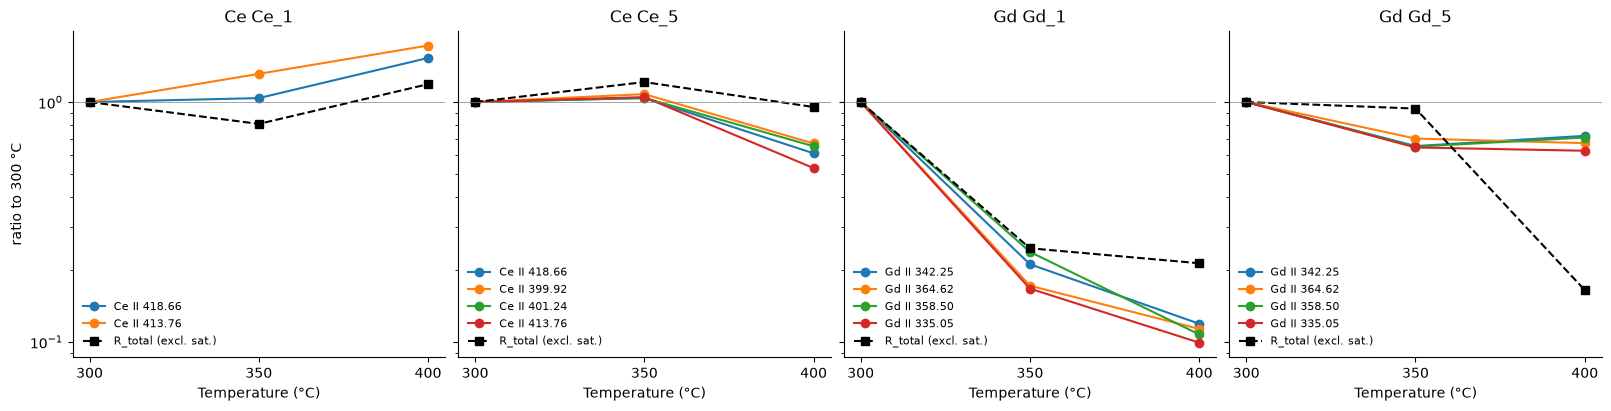

In [9]:
plot_study(result)

Check the baseline on one spectrum. The top panel shows the fitted continuum; the bottom one is what the *Total* area integrates. Change `method` to compare SNIP and airPLS.

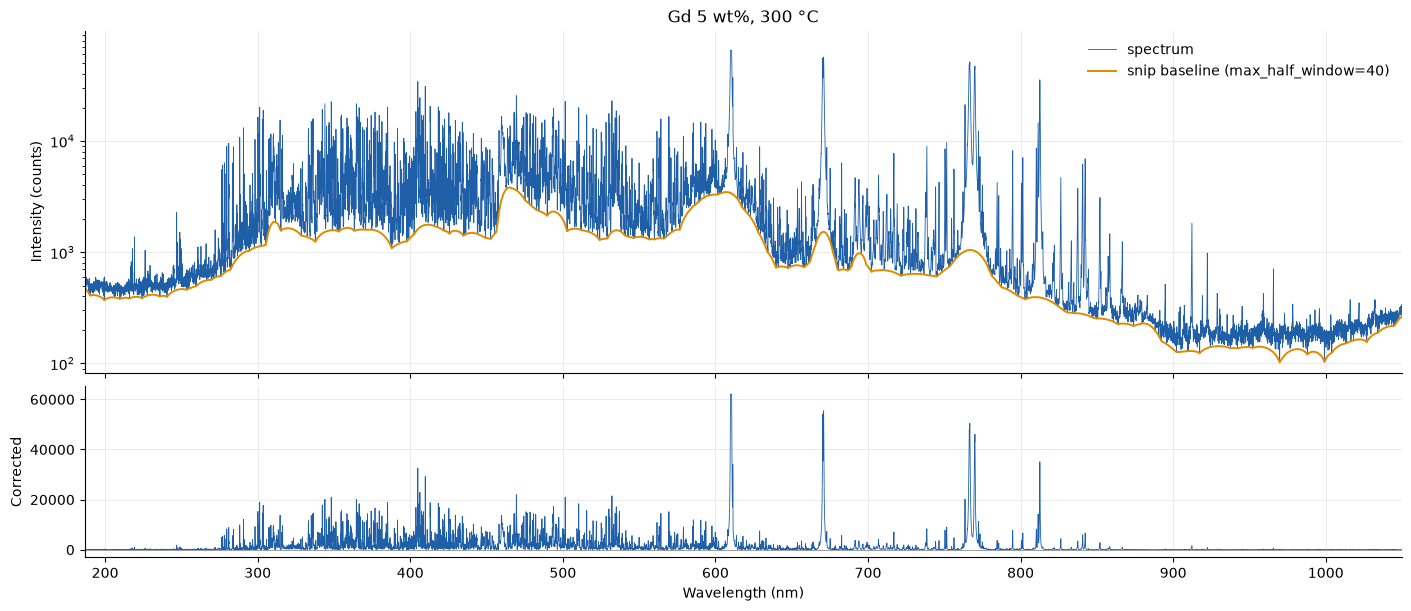

In [10]:
plot_baseline(result.wl, result.spectra['Gd Gd_5'][300], method=result.settings['baseline'],
              title='Gd 5 wt%, 300 °C')

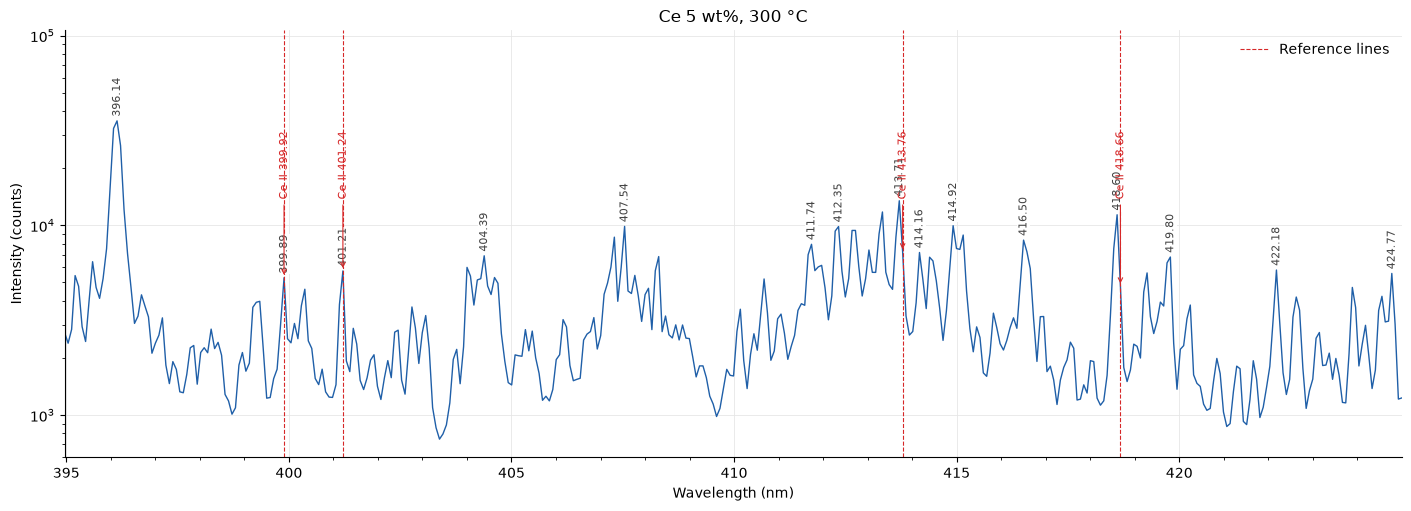

In [11]:
plot_spectrum(result.wl, result.spectra['Ce Ce_5'][300], ref_lines=result.lines['Ce Ce_5'],
              wl_range=(395, 425), title='Ce 5 wt%, 300 °C')

## 5. Save

`save` writes every table as CSV, plus `settings.json` (inputs, versions, picked lines, notes) and `summary.txt`. It refuses to write inside the data folder. `output/` is ignored by git.

In [12]:
written = result.save(ROOT / 'output' / 'end_to_end_snip')
[p.name for p in written]

['plan.csv',
 'overview.csv',
 'areas.csv',
 'R_direct.csv',
 'R_rel.csv',
 'scatter.csv',
 'lines_Ce.csv',
 'lines_Gd.csv',
 'settings.json',
 'summary.txt']

## Same thing from a terminal

```
libs-viewer analyze data/end_to_end --pattern "{element}/{sample}/*{temperature}*" ^
    --temperatures 300 350 400 --elements Ce Gd --baseline snip --out output/end_to_end_snip
```

Use `--manifest` (a CSV with columns `file, element, sample, temperature[, use_columns]`) instead of `--pattern` when the file names have no usable pattern. [end_to_end_manifest.csv](end_to_end_manifest.csv) is an example for this folder:

```
libs-viewer analyze data/end_to_end --manifest examples/end_to_end_manifest.csv ^
    --baseline snip --out output/end_to_end_manifest
```